**SAPIANS** · SCC5819 · MÓDULO 07 — ALE · MOLNAR, CAP. 20

# ALE por dentro — bordas, acúmulo e origem da curva

O módulo de PDP conferiu uma média marginal. O walkthrough de ALE adotou
um acúmulo de diferenças locais; aqui reconstruímos essa operação e separamos
a convenção do curso dos detalhes numéricos de iml.

[README do módulo](../README.md) · [outline da aula](../lecture/outline.md) · [Colab](https://colab.research.google.com/github/wbendinelli/interpretable-ml-lectures/blob/main/modules/07-ale/notebooks/ale_internals.ipynb)

---

**Objetivos.** Conferir máscaras de intervalos, bordas e quantis repetidos;
recalcular acúmulo e centralização sem chamar o núcleo; separar associação
de sensibilidade no controle conhecido; comparar as convenções de iml.

In [1]:
%pip install -q numpy pandas pyarrow scikit-learn xgboost matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import hashlib
import inspect
import itertools
import os
import pathlib
import subprocess
import sys
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import log_loss
from xgboost import XGBClassifier

RANDOM_STATE = 42
REPO = pathlib.Path(
    os.environ.get("INTERPRETABLE_ML_REPO", pathlib.Path.cwd())
).resolve()
while REPO != REPO.parent and not (REPO / "tools/README.md").exists():
    REPO = REPO.parent
if not (REPO / "tools/README.md").exists():
    REPO = pathlib.Path(tempfile.gettempdir()) / "interpretable-ml-lectures"
    if not REPO.exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "https://github.com/wbendinelli/interpretable-ml-lectures.git",
                str(REPO),
            ],
            check=True,
            capture_output=True,
        )
sys.path.insert(0, str(REPO / "tools"))
import sapians as SP
import srag_60_model as M
import srag_71_global_effects as G

# Tudo que é gerado fica fora da árvore de trabalho; só cópias explícitas são publicadas.
WORK = pathlib.Path(
    os.environ.get("GLOBAL_EFFECTS_WORK", tempfile.mkdtemp(prefix="global-effects-"))
)
os.chdir(WORK)
SP.aplicar(tema="global")
print("Perfil visual: SAPIANS Global / VITA | fonte:", SP.FONTE_ATUAL)

Perfil visual: SAPIANS Global / VITA | fonte: Satoshi


## §1 — Mesmo dado, mesmo preditor, pergunta global

A amostra Gold do módulo da base e a receita histórica são reutilizadas sem seleção ou balanceamento adicional. A ordem por identificador precede o sorteio; o alvo não orienta a escolha das fichas. O fundo integra as outras entradas. Painel e fundo são amostras de explicação do teste temporal, não novas partições para selecionar modelos.

In [3]:
path = REPO / "modules/00-dataset/gold/gold_covid_obito_sample.parquet"
gold = M.load_gold(path)
x, _, y = M.design_matrix(gold)
tr = (gold["split"] == "train").to_numpy()
te = (gold["split"] == "test").to_numpy()
model = XGBClassifier(**M.XGB_PARAMS).fit(x.loc[tr], y[tr])
model_bytes = bytes(model.get_booster().save_raw())


def prever(frame):
    return np.asarray(model.predict_proba(frame[list(M.FEATURES)])[:, 1], dtype=float)


teste = gold.loc[te].sort_values("gold_id").reset_index(drop=True)
# Sorteio independente do alvo, do erro e da magnitude dos efeitos.
painel = teste.sample(n=512, random_state=RANDOM_STATE).reset_index(drop=True)
fundo = painel.iloc[:256].copy()
xf = M.design_matrix(fundo)[0]
xp = M.design_matrix(painel)[0]
original_xf = xf.copy(deep=True)
print("SHA256 da amostra:", hashlib.sha256(path.read_bytes()).hexdigest())
print("SHA256 do preditor desta execução:", hashlib.sha256(model_bytes).hexdigest())
print("Semente:", SP.pt_int(RANDOM_STATE))
print("Treino até:", str(2022), "| validação:", str(2023), "| teste:", str(2024))
print(
    "Treino:",
    SP.pt_int(tr.sum()),
    "| validação:",
    SP.pt_int((gold["split"] == "val").sum()),
)
print("Teste completo:", SP.pt_int(te.sum()), "| óbitos:", SP.pt_int(y[te].sum()))
print(
    "Entradas:",
    SP.pt_int(len(M.FEATURES)),
    "| painel:",
    SP.pt_int(len(painel)),
    "| fundo:",
    SP.pt_int(len(fundo)),
)
print("Log loss do teste completo:", SP.pt(log_loss(y[te], prever(x.loc[te])), 6))
print("Previsão média no painel:", SP.pct(prever(xp).mean()))
print(
    "Versões:",
    "Python",
    sys.version.split()[0],
    "| numpy",
    np.__version__,
    "| pandas",
    pd.__version__,
)
print("Alvo não participa das curvas; teste já observado, análise exploratória.")

SHA256 da amostra: cb79c99338a5a7b3c125659aad148a73749e2695f2048c9481a20ab29e3ca918
SHA256 do preditor desta execução: 55b1c49045b8b6368d61eb91073beaaf6197c0081613ad688670eaefe5e91007
Semente: 42
Treino até: 2022 | validação: 2023 | teste: 2024
Treino: 200.000 | validação: 24.148
Teste completo: 16.142 | óbitos: 2.945
Entradas: 40 | painel: 512 | fundo: 256
Log loss do teste completo: 0,409020
Previsão média no painel: 21,9%
Versões: Python 3.12.13 | numpy 2.4.6 | pandas 2.3.3
Alvo não participa das curvas; teste já observado, análise exploratória.


**O que olhar.**

- Os tamanhos impressos distinguem o treino do modelo, o teste completo e o orçamento da explicação.
- O log loss identifica o preditor; as curvas abaixo descrevem suas previsões, sem estimar efeitos clínicos.

## §2 — Reconstruir sem chamar o núcleo

Uma segunda implementação faz máscaras e somas diretamente, usando as bordas devolvidas apenas para fixar o mesmo estimando. A centralização é recalculada por linha. Também exercitamos valores nas bordas e quantis repetidos.

In [4]:
tab, assigned = G.ale_numerica(prever, xp, "idade_anos", bins=10)
v = xp["idade_anos"].to_numpy()
deltas = []
idx = np.zeros(len(xp), dtype=int)
for k, row in tab.iterrows():
    mask = (v >= row.esquerda if k == 0 else v > row.esquerda) & (v <= row.direita)
    local = xp.loc[mask].copy()
    baixo, alto = local.copy(), local.copy()
    baixo["idade_anos"] = np.float32(row.esquerda)
    alto["idade_anos"] = np.float32(row.direita)
    deltas.append(np.mean(prever(alto) - prever(baixo)))
    idx[mask] = k
raw = np.cumsum(deltas)[idx]
ref = raw - raw.mean()
assert np.allclose(ref, assigned, atol=1e-12)
print(
    "Erro máximo da reconstrução independente:",
    SP.pt_sig(np.max(np.abs(ref - assigned)), 4),
)
repetidos = pd.DataFrame({"a": [0.0, 0.0, 0.0, 1.0, 1.0, 2.0, 2.0, 2.0]})


def linear(d):
    return 3 * d["a"].to_numpy() + 7


try:
    G.ale_numerica(linear, repetidos, "a", bins=12)
except ValueError as exc:
    assert "Intervalo vazio" in str(exc)
    print("Grade refinada recusada por intervalo vazio:", True)
else:
    raise AssertionError("O controle deveria recusar intervalos vazios.")
t, a = G.ale_numerica(linear, repetidos, "a", bins=3)
assert t["n"].sum() == len(repetidos) and (t["n"] > 0).all()
assert np.allclose(t["delta"], 3 * (t["direita"] - t["esquerda"]))
const, ca = G.ale_numerica(linear, pd.DataFrame({"a": [1.0, 1.0, 1.0]}), "a", bins=10)
assert np.array_equal(ca, np.zeros(3))
print("Quantis repetidos: intervalos efetivos:", SP.pt_int(len(t)))
print("Centralização com empates:", SP.pt_sig(a.mean(), 4))
print("Amplitude para entrada constante:", SP.pt(np.ptp(ca), 6))
print(SP.tabela(t, casas=4))

Erro máximo da reconstrução independente: 0,0000
Grade refinada recusada por intervalo vazio: True
Quantis repetidos: intervalos efetivos: 3
Centralização com empates: -3,3307×10⁻¹⁶
Amplitude para entrada constante: 0,000000
esquerda direita n  delta     ale
  0,0000  0,3333 3 1,0000 -2,8750
  0,3333  1,6667 2 4,0000  1,1250
  1,6667  2,0000 3 1,0000  2,1250


**O que olhar.**

- O erro impresso compara duas rotas de cálculo, inclusive a atribuição nas bordas.
- A entrada constante produz efeito nulo; uma categoria nominal não é encaminhada à rotina numérica.

## §3 — Dependência com fórmula conhecida

No controle, b acompanha a. O preditor depende somente de b: o M-plot cresce com a, enquanto PDP e ALE de a ficam planos. Isso separa associação e sensibilidade do preditor.

Amplitude ALE da entrada ignorada: 0,000000
Amplitude M-plot associativo: 3,610000


figura: figures_generated/ale-controle-dependente.png


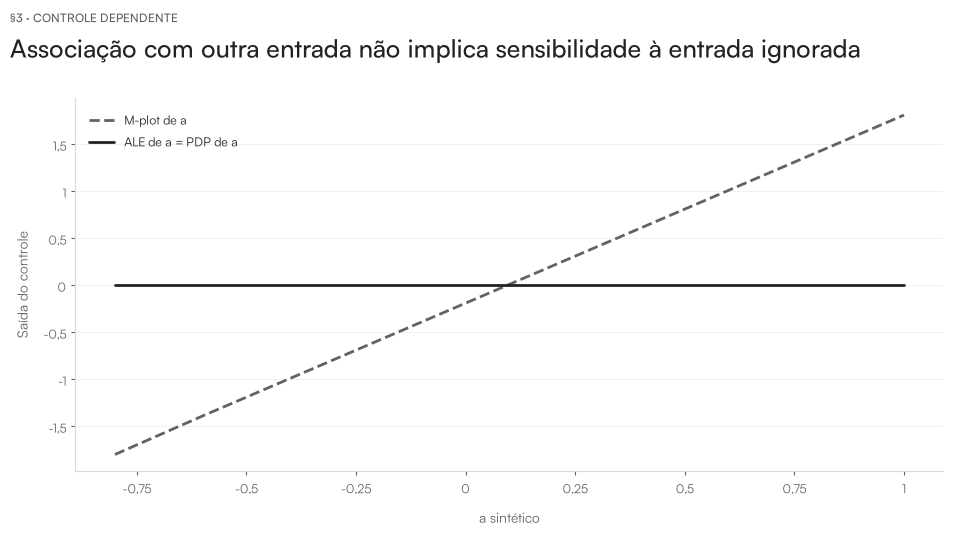

In [5]:
a = np.linspace(-1, 1, 201)
dep = pd.DataFrame({"a": a, "b": 2 * a})


def so_b(d):
    return d["b"].to_numpy()


t, values = G.ale_numerica(so_b, dep, "a", bins=10)
pd_a = G.pd_empirica(so_b, dep, pd.DataFrame({"a": t["direita"]}))
group = pd.cut(
    dep["a"], bins=np.r_[t["esquerda"].iloc[0], t["direita"]], include_lowest=True
)
mplot = dep.groupby(group, observed=True)["b"].mean().to_numpy()
assert np.allclose(values, 0) and np.allclose(pd_a, 0)
print("Amplitude ALE da entrada ignorada:", SP.pt(np.ptp(values), 6))
print("Amplitude M-plot associativo:", SP.pt(np.ptp(mplot), 6))
fig, ax = plt.subplots(figsize=SP.SLOT)
ax.plot(t["direita"], mplot, color=SP.CINZA, linestyle="--", label="M-plot de a")
ax.plot(t["direita"], t["ale"], color=SP.ESCURO, label="ALE de a = PDP de a")
ax.set(xlabel="a sintético", ylabel="Saída do controle")
ax.legend()
SP.titulo(
    fig,
    "Associação com outra entrada não implica sensibilidade à entrada ignorada",
    "§3 · Controle dependente",
)
SP.salvar(fig, "ale-controle-dependente")
plt.show()

**O que olhar.**

- O contraste entre amplitudes confere o mecanismo usando uma função conhecida.
- O resultado não demonstra que ALE isola efeitos causais em dados observacionais.

### O que o livro diz

O [capítulo de Molnar](https://christophm.github.io/interpretable-ml-book/ale.html)
separa diferenças locais da média condicional das previsões. O controle em que
o preditor ignora a entrada estudada torna essa distinção explícita: associação
entre entradas não basta para produzir sensibilidade do modelo à entrada alterada.

Na aplicação discreta, bordas e centralização fazem parte do estimador. O curso
atribui o degrau da borda superior; a tradução de iml confere sua convenção
própria. Mantemos essa diferença e a ausência de execução nativa em R explícitas.
Nenhum desses controles demonstra que ALE isola efeitos causais.

## §4 — O estimador discreto do livro e a convenção de iml

A fórmula em degraus do capítulo acumula até a borda superior do intervalo que contém cada ficha e centraliza os efeitos atribuídos. É a convenção adotada aqui. O código `calculate.ale.num` de iml centraliza pela média ponderada dos efeitos nos pontos médios dos intervalos e devolve ambas as bordas extremas. Além disso, `get.grid.1D` usa quantis R tipo 1 (inversa da CDF empírica); nosso núcleo usa quantis lineares.

A tradução abaixo confere separadamente a centralização na mesma grade e o padrão de quantis do pacote. Não executa R. Na mesma grade, a diferença deve ser uma constante vertical; comparar curvas como se tivessem a mesma origem seria incorreto. O módulo mantém sua convenção didática explícita.


In [6]:
def ale_iml_traduzida(base, bordas):
    # FeatureEffect-ale.R: diferenças por ficha, média local, acumulação,
    # centro pelos pontos médios dos efeitos; utils.R: quantis tipo 1.
    v = base["idade_anos"].to_numpy()
    grupos = np.searchsorted(bordas, v, side="left") - 1
    grupos[grupos < 0] = 0
    inferior, superior = base.copy(deep=True), base.copy(deep=True)
    inferior["idade_anos"] = bordas[grupos].astype(v.dtype)
    superior["idade_anos"] = bordas[grupos + 1].astype(v.dtype)
    dif = prever(superior) - prever(inferior)
    contagens = np.bincount(grupos, minlength=len(bordas) - 1)
    assert (contagens > 0).all()
    deltas = np.bincount(grupos, weights=dif) / contagens
    bruto = np.r_[0, np.cumsum(deltas)]
    centro = np.average((bruto[:-1] + bruto[1:]) / 2, weights=contagens)
    return bruto - centro, deltas, contagens


bordas = np.r_[tab["esquerda"].iloc[0], tab["direita"]]
ref_iml, delta_iml, counts_iml = ale_iml_traduzida(xp, bordas)
diferenca = ref_iml[1:] - tab["ale"].to_numpy()
assert np.allclose(delta_iml, tab["delta"], atol=1e-12)
assert np.array_equal(counts_iml, tab["n"])
assert np.ptp(diferenca) < 1e-12
print(
    "Erro máximo nas diferenças locais, mesma grade:",
    SP.pt_sig(np.max(np.abs(delta_iml - tab["delta"])), 4),
)
print(
    "Deslocamento iml menos degraus do curso, p.p.:", SP.pt(100 * diferenca.mean(), 6)
)
print("Variação desse deslocamento, p.p.:", SP.pt_sig(100 * np.ptp(diferenca), 4))
print(
    "Amplitude nas bordas superiores, curso e iml, p.p.:",
    SP.pt(100 * np.ptp(tab["ale"]), 6),
    SP.pt(100 * np.ptp(ref_iml[1:]), 6),
)
bordas_tipo1 = np.unique(
    np.quantile(xp["idade_anos"], np.linspace(0, 1, 11), method="inverted_cdf")
)
ref_padrao, _, counts_padrao = ale_iml_traduzida(xp, bordas_tipo1)
print(
    "Quantis lineares vs tipo 1: máximo desvio de borda em anos:",
    SP.pt(np.max(np.abs(bordas - bordas_tipo1)), 6),
)
print(
    "Amplitude iml tipo 1 incluindo ambas as bordas, p.p.:",
    SP.pt(100 * np.ptp(ref_padrao), 6),
)
print("Menor contagem, quantis tipo 1:", SP.pt_int(counts_padrao.min()))
# Regressão encontrada na auditoria: uma grade fracionária não pode ser
# truncada por uma coluna de armazenamento inteira.
controle_int = pd.DataFrame({"a": [0, 1, 2, 3]})
ti, _ = G.ale_numerica(lambda d: d["a"].to_numpy(), controle_int, "a", bins=2)
assert np.allclose(ti["delta"], ti["direita"] - ti["esquerda"])
print("Diferenças ALE com bordas fracionárias e coluna inteira corretas:", True)
for invalida in [
    pd.DataFrame({"a": [True, False]}),
    pd.DataFrame({"a": [0.0, np.nan]}),
]:
    try:
        G.ale_numerica(lambda d: np.zeros(len(d)), invalida, "a")
    except ValueError:
        pass
    else:
        raise AssertionError("Entrada inválida não foi recusada")
print("Booleanos e ausências recusados:", True)

Erro máximo nas diferenças locais, mesma grade: 0,0000
Deslocamento iml menos degraus do curso, p.p.: 1,688792
Variação desse deslocamento, p.p.: 0,0000
Amplitude nas bordas superiores, curso e iml, p.p.: 34,676392 34,676392
Quantis lineares vs tipo 1: máximo desvio de borda em anos: 0,253799
Amplitude iml tipo 1 incluindo ambas as bordas, p.p.: 34,709600
Menor contagem, quantis tipo 1: 51
Diferenças ALE com bordas fracionárias e coluna inteira corretas: True
Booleanos e ausências recusados: True


## Fechamento — mesma diferença local não implica mesma origem

- A reconstrução independente confere atribuição às janelas, acúmulo e média
  centralizadora, incluindo os casos de borda.
- A comparação com iml separa a escolha dos quantis da centralização. Curvas
  com origens diferentes não devem ser tratadas como valores idênticos.
- O controle conhecido distingue associação observada de resposta à entrada.
  As recusas de entradas inválidas verificam o domínio da rotina numérica;
  não certificam plausibilidade clínica ou causalidade.

In [7]:
pd.testing.assert_frame_equal(xf, original_xf)
assert bytes(model.get_booster().save_raw()) == model_bytes
print("Matriz de fundo e preditor permaneceram intactos:", True)

Matriz de fundo e preditor permaneceram intactos: True


## Referências

Molnar — [cap. 20](https://christophm.github.io/interpretable-ml-book/ale.html). Referências completas e configuração no [README](../README.md).